### Load in Required Packages

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import os

### Read in Summary Results

Load in results (from Isolating_mesh_batch.py) so they can be inspected and analyzed in the following steps.

In [2]:
# RESULTS_PATH = "results/elevation_azimuth_angles.pkl"
# RESULTS_PATH = "results/elevation_azimuth_angles_wTrace_updated.pkl"
RESULTS_PATH = "elevation_azimuth_angles_v2_wTrace.pkl"
df = pd.read_pickle(RESULTS_PATH)
print(f"Loaded {len(df)} result rows from: {RESULTS_PATH}")
print(df.columns)

Loaded 1100 result rows from: elevation_azimuth_angles_v2_wTrace.pkl
Index(['expected_elevation_angle_deg', 'expected_azimuth_angle_deg',
       'wind_speed_mps', 'simulation_time_s', 'avg_facet_normal_x',
       'avg_facet_normal_y', 'avg_facet_normal_z', 'elevation_angle_deg',
       'el_tracking_error_mrad', 'azimuth_angle_deg', 'az_tracking_error_mrad',
       'total_tracking_error_mrad', 'slope_error_mean_mrad',
       'slope_error_std_mrad', 'slope_error_mean_weighted_mrad',
       'slope_error_std_weighted_mrad', 'n_facet_faces', 'n_facet_vertices',
       'original_mesh_path', 'isolated_mesh_path', 'ST_results'],
      dtype='str')


### Create Grouped Results

Averaging tracking errors and slope errors over the simulation timesteps

In [3]:
# sim_avg_path = "results/sim_avg_results"
sim_avg_path = "grouped_avg_results_v4"
sim_avg_results = df.drop(columns=["simulation_time_s", 
                                   "n_facet_vertices",
                                   "n_facet_faces", 
                                   "n_facet_vertices"]).groupby(["expected_elevation_angle_deg", 
                                                                 "expected_azimuth_angle_deg", 
                                                                 "wind_speed_mps"]).mean(numeric_only=True)
sim_avg_results.to_pickle(sim_avg_path + ".pkl")
sim_avg_results.to_csv(sim_avg_path + ".csv")
display(sim_avg_results)

avg_facet_normal_x  \
expected_elevation_angle_deg expected_azimuth_angle_deg wind_speed_mps                       
15.0                         0.0                        4.0                      -0.965614   
                                                        8.0                      -0.965571   
                                                        12.0                     -0.965500   
                                                        16.0                     -0.965400   
                             15.0                       4.0                      -0.932702   
                                                        8.0                      -0.932643   
                                                        12.0                     -0.932544   
                                                        16.0                     -0.932405   
                             30.0                       4.0                      -0.836246   
                                                        8.0                      -0.836235   
                                                        12.0                     -0.836216   
                                                        16.0                     -0.836189   
                             45.0                       4.0                      -0.682806   
                                                        8.0                      -0.682845   
                                                        12.0                     -0.682921   
                                                        16.0                     -0.683023   
                             60.0                       4.0                      -0.482854   
                                                        8.0                      -0.483025   
                                                        12.0                     -0.483322   
                                                        16.0                     -0.483711   
30.0                         0.0                        4.0                      -0.865357   
                                                        8.0                      -0.865307   
                                                        12.0                     -0.865223   
                                                        16.0                     -0.865105   
                             15.0                       4.0                      -0.835858   
                                                        8.0                      -0.835771   
                                                        12.0                     -0.835627   
                                                        16.0                     -0.835425   
                             30.0                       4.0                      -0.749420   
                                                        8.0                      -0.749378   
                                                        12.0                     -0.749293   
                                                        16.0                     -0.749227   
                             60.0                       4.0                      -0.432682   
                                                        8.0                      -0.432747   
                                                        12.0                     -0.432854   
                                                        16.0                     -0.433004   
45.0                         0.0                        4.0                      -0.705999   
                                                        8.0                      -0.705963   
                                                        12.0                     -0.705904   
                                                        16.0                     -0.705816   
                             60.0                       4.0                      -0.353009   
                              

### Pull Group Values to Loop Through

Create results directory structure

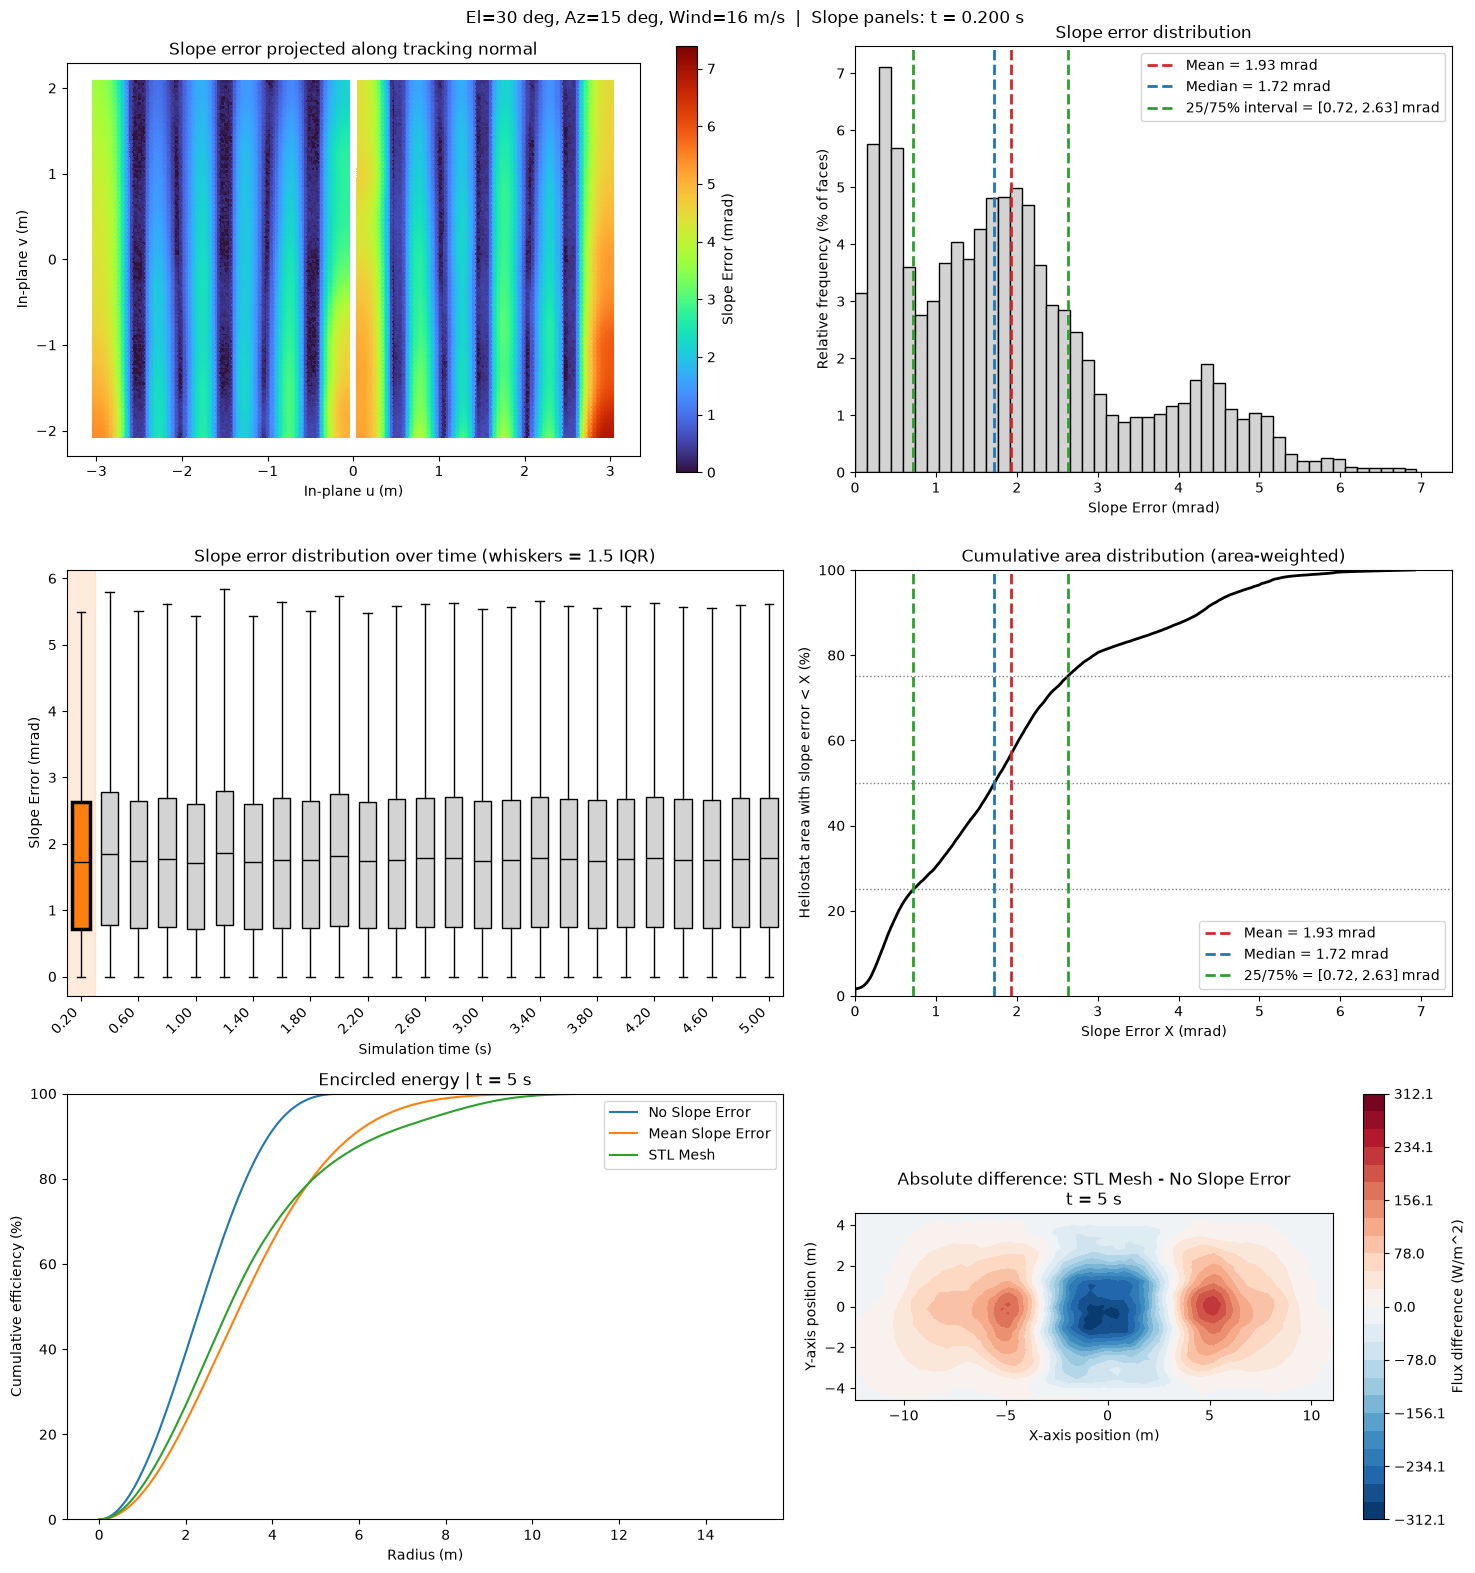

In [4]:
import trimesh
import matplotlib.pyplot as plt
import ipywidgets as widgets
from functools import lru_cache
from io import BytesIO
from IPython.display import Image, display


groups = df.groupby(["expected_elevation_angle_deg", "expected_azimuth_angle_deg", "wind_speed_mps"])
keys = list(groups.groups.keys())

N_HIST_BINS = 50
MAX_BOX_TICKS = 20
FIGURE_DIR = Path("results/figures")
FIGURE_DPI = 200
TRACE_TIME_S = 5.0
MAX_CURVE_POINTS = 2000
TRACE_LABELS = {
    "ST_baseline": "No Slope Error",
    "ST_mean_slope_error": "Mean Slope Error",
    "ST_mesh": "STL Mesh",
}
FLUX_OPTIONS = [(label, name) for name, label in TRACE_LABELS.items()]
for reference in ("ST_baseline", "ST_mean_slope_error"):
    for mode in ("absolute", "relative"):
        FLUX_OPTIONS.append((
            f"{mode.title()} difference: STL Mesh - {TRACE_LABELS[reference]}",
            f"{mode}:{reference}",
        ))


def in_plane_basis(normal):
    # Orthonormal (u, v) spanning the plane perpendicular to the normal; y is the global up axis
    ref = np.array([0.0, 1.0, 0.0]) if abs(normal[1]) < 0.9 else np.array([1.0, 0.0, 0.0])
    u = np.cross(ref, normal)
    u /= np.linalg.norm(u)
    v = np.cross(normal, u)
    return u, v


@lru_cache(maxsize=None)
def load_case(key):
    """Load every timestep of a case, projecting the mesh onto the plane normal to the tracking normal."""
    case = groups.get_group(key).sort_values("simulation_time_s")
    steps = []
    for _, row in case.iterrows():
        tracking_normal = row[["avg_facet_normal_x", "avg_facet_normal_y", "avg_facet_normal_z"]].to_numpy(dtype=float)
        tracking_normal /= np.linalg.norm(tracking_normal)

        #print(f"Loading mesh for simulation time {row['simulation_time_s']:.3f} s from {row['isolated_mesh_path']}")
        mesh = trimesh.load(row["isolated_mesh_path"])
        slope_error_mrad = np.arccos(np.clip(mesh.face_normals @ tracking_normal, -1.0, 1.0)) * 1000.0

        u, v = in_plane_basis(tracking_normal)
        pts = mesh.vertices - mesh.vertices.mean(axis=0)
        xy = np.column_stack((pts @ u, pts @ v))

        steps.append({"t": row["simulation_time_s"], "xy": xy, "faces": np.asarray(mesh.faces),
                      "se": slope_error_mrad, "area": np.asarray(mesh.area_faces)})

    all_se = np.concatenate([s["se"] for s in steps])
    return steps, float(all_se.min()), float(all_se.max())


def plot_trace_panels(fig, ax_energy, ax_flux, key, cumulative_metric, flux_choice):
    ax_energy.set_title(f"Encircled energy | t = {TRACE_TIME_S:g} s")
    ax_energy.set_xlabel("Radius (m)")
    ax_energy.set_ylabel("Cumulative power (kW)" if cumulative_metric == "cumulative_power"
                         else "Cumulative efficiency (%)")
    ax_flux.set_xlabel("X-axis position (m)")
    ax_flux.set_ylabel("Y-axis position (m)")
    case = groups.get_group(key)
    trace_rows = case.loc[np.isclose(case["simulation_time_s"], TRACE_TIME_S, rtol=0.0, atol=1e-6)]
    trace_results = next((value for value in trace_rows.get("ST_results", [])
                          if isinstance(value, dict)), None)
    if trace_results is None:
        for axis in (ax_energy, ax_flux):
            axis.text(0.5, 0.5, "No ray-tracing results at t = 5 s",
                      transform=axis.transAxes, ha="center", va="center")
        ax_flux.set_title(f"Receiver flux | t = {TRACE_TIME_S:g} s")
        return

    for name, label in TRACE_LABELS.items():
        result = trace_results[name]
        radius = np.asarray(result["radius"])
        values = np.asarray(result[cumulative_metric])
        sample_idx = np.linspace(0, len(radius) - 1, min(len(radius), MAX_CURVE_POINTS), dtype=int)
        scale = 100.0 if cumulative_metric == "cumulative_efficiency" else 1.0
        ax_energy.plot(radius[sample_idx], values[sample_idx] * scale, label=label)
    if cumulative_metric == "cumulative_efficiency":
        ax_energy.set_ylim(0, 100)
    ax_energy.legend()

    if ":" in flux_choice:
        mode, reference = flux_choice.split(":", 1)
        mesh_flux = np.asarray(trace_results["ST_mesh"]["flux_map (kW/m^2)"]) * 1000.0
        reference_flux = np.asarray(trace_results[reference]["flux_map (kW/m^2)"]) * 1000.0
        flux = mesh_flux - reference_flux
        title = f"STL Mesh - {TRACE_LABELS[reference]}"
        colorbar_label = "Flux difference (W/m^2)"
        if mode == "relative":
            mean_mesh_flux = mesh_flux.mean()
            if mean_mesh_flux <= 0:
                ax_flux.text(0.5, 0.5, "Relative difference unavailable: zero mean mesh flux",
                             transform=ax_flux.transAxes, ha="center", va="center", wrap=True)
                ax_flux.set_title(f"Relative flux difference | t = {TRACE_TIME_S:g} s")
                return
            flux = flux / mean_mesh_flux
            colorbar_label = "Flux difference / mean STL Mesh flux (-)"
        limit = max(float(np.max(np.abs(flux))), np.finfo(float).eps)
        levels = np.linspace(-limit, limit, 25)
        cmap = "RdBu_r"
        title = f"{mode.title()} difference: {title}"
    else:
        flux = np.asarray(trace_results[flux_choice]["flux_map (kW/m^2)"]) * 1000.0
        title = TRACE_LABELS[flux_choice]
        colorbar_label = "Flux (W/m^2)"
        levels = 25
        cmap = "turbo"

    width, height = trace_results["receiver_aperture"]
    x_rec = -width / 2.0 + (np.arange(flux.shape[0]) + 0.5) * width / flux.shape[0]
    y_rec = -height / 2.0 + (np.arange(flux.shape[1]) + 0.5) * height / flux.shape[1]
    contour = ax_flux.contourf(x_rec, y_rec, flux.T, levels=levels, cmap=cmap)
    fig.colorbar(contour, ax=ax_flux, label=colorbar_label)
    active_bins = np.isfinite(flux) & (flux != 0)
    active_x, active_y = np.where(active_bins)
    if active_x.size:
        dx = width / flux.shape[0]
        dy = height / flux.shape[1]
        ax_flux.set_xlim(x_rec[active_x.min()] - dx / 2.0,
                         x_rec[active_x.max()] + dx / 2.0)
        ax_flux.set_ylim(y_rec[active_y.min()] - dy / 2.0,
                         y_rec[active_y.max()] + dy / 2.0)
    ax_flux.set_aspect("equal")
    ax_flux.set_title(f"{title}\nt = {TRACE_TIME_S:g} s")


def figure_path(key, t):
    el, az, w = key
    case_dir = FIGURE_DIR / f"el{el:g}_az{az:g}_wind{w:g}mps"
    case_dir.mkdir(parents=True, exist_ok=True)
    return case_dir / f"t_{t:08.3f}s.png"


def make_figure(key, idx, cumulative_metric="cumulative_efficiency", flux_choice="ST_mesh"):
    steps, vmin, vmax = load_case(key)
    idx = min(idx, len(steps) - 1)
    s = steps[idx]
    se = s["se"]
    elkey, azkey, windkey = key

    fig, axes = plt.subplots(3, 2, figsize=(15, 16), gridspec_kw={"width_ratios": [1.2, 1]})
    (ax_map, ax_hist), (ax_box, ax_cum), (ax_energy, ax_flux) = axes

    # Top-left: 2D projected slope error map (shared color scale across all timesteps)
    tpc = ax_map.tripcolor(s["xy"][:, 0], s["xy"][:, 1], s["faces"], facecolors=se,
                           cmap="turbo", vmin=vmin, vmax=vmax)
    fig.colorbar(tpc, ax=ax_map, label="Slope Error (mrad)")
    ax_map.set_aspect("equal")
    ax_map.set_xlabel("In-plane u (m)")
    ax_map.set_ylabel("In-plane v (m)")
    ax_map.set_title("Slope error projected along tracking normal")

    # Top-right: relative frequency histogram (shared bins across all timesteps)
    mean, median = se.mean(), np.median(se)
    lo, hi = np.percentile(se, [25.0, 75.0])
    ax_hist.hist(se, bins=np.linspace(vmin, vmax, N_HIST_BINS + 1), weights=np.full(se.size, 100.0 / se.size),
                 color="lightgray", edgecolor="black")
    ax_hist.axvline(mean, color="tab:red", ls="--", lw=2, label=f"Mean = {mean:.2f} mrad")
    ax_hist.axvline(median, color="tab:blue", ls="--", lw=2, label=f"Median = {median:.2f} mrad")
    ax_hist.axvline(lo, color="tab:green", ls="--", lw=2, label=f"25/75% interval = [{lo:.2f}, {hi:.2f}] mrad")
    ax_hist.axvline(hi, color="tab:green", ls="--", lw=2)
    ax_hist.set_xlim(vmin, vmax)
    ax_hist.set_xlabel("Slope Error (mrad)")
    ax_hist.set_ylabel("Relative frequency (% of faces)")
    ax_hist.set_title("Slope error distribution")
    ax_hist.legend()

    # Bottom-left: slope error distribution over time, selected timestep highlighted
    times = [st["t"] for st in steps]
    bp = ax_box.boxplot([st["se"] for st in steps], positions=np.arange(len(steps)), patch_artist=True,
                        showfliers=False, widths=0.6, medianprops={"color": "black"})
    for i, box in enumerate(bp["boxes"]):
        box.set_facecolor("tab:orange" if i == idx else "lightgray")
        box.set_edgecolor("black")
        box.set_linewidth(2.5 if i == idx else 1.0)
    ax_box.axvspan(idx - 0.5, idx + 0.5, color="tab:orange", alpha=0.15, zorder=0)
    tick_step = max(1, int(np.ceil(len(steps) / MAX_BOX_TICKS)))
    tick_idx = np.arange(0, len(steps), tick_step)
    ax_box.set_xticks(tick_idx)
    ax_box.set_xticklabels([f"{times[i]:.2f}" for i in tick_idx], rotation=45, ha="right")
    ax_box.set_xlabel("Simulation time (s)")
    ax_box.set_ylabel("Slope Error (mrad)")
    ax_box.set_title("Slope error distribution over time (whiskers = 1.5 IQR)")

    # Bottom-right: cumulative heliostat area with slope error below X (area-weighted)
    order = np.argsort(se)
    se_sorted = se[order]
    area_sorted = s["area"][order]
    cum_pct = np.cumsum(area_sorted) / area_sorted.sum() * 100.0
    ax_cum.plot(se_sorted, cum_pct, color="black", lw=2)
    a_mean = np.average(se, weights=s["area"])
    a_q1, a_med, a_q3 = np.interp([25.0, 50.0, 75.0], cum_pct, se_sorted)
    ax_cum.axvline(a_mean, color="tab:red", ls="--", lw=2, label=f"Mean = {a_mean:.2f} mrad")
    ax_cum.axvline(a_med, color="tab:blue", ls="--", lw=2, label=f"Median = {a_med:.2f} mrad")
    ax_cum.axvline(a_q1, color="tab:green", ls="--", lw=2, label=f"25/75% = [{a_q1:.2f}, {a_q3:.2f}] mrad")
    ax_cum.axvline(a_q3, color="tab:green", ls="--", lw=2)
    for q in (25.0, 50.0, 75.0):
        ax_cum.axhline(q, color="gray", ls=":", lw=1)
    ax_cum.set_xlim(vmin, vmax)
    ax_cum.set_ylim(0, 100)
    ax_cum.set_xlabel("Slope Error X (mrad)")
    ax_cum.set_ylabel("Heliostat area with slope error < X (%)")
    ax_cum.set_title("Cumulative area distribution (area-weighted)")
    ax_cum.legend(loc="lower right")

    plot_trace_panels(fig, ax_energy, ax_flux, key, cumulative_metric, flux_choice)
    fig.suptitle(f"El={elkey:g} deg, Az={azkey:g} deg, Wind={windkey:g} m/s  |  Slope panels: t = {s['t']:.3f} s")
    fig.tight_layout()
    return fig, s["t"]


plot_display = None


def plot_timestep(key, idx, cumulative_metric, flux_choice):
    global plot_display
    if idx is None:
        return
    fig, t = make_figure(key, idx, cumulative_metric, flux_choice)
    try:
        if save_checkbox.value:
            path = figure_path(key, t)
            fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
            print(f"Saved: {path}")
        with BytesIO() as buffer:
            fig.savefig(buffer, format="png", dpi=100, bbox_inches="tight")
            image = Image(data=buffer.getvalue())
        if plot_display is None:
            plot_display = display(image, display_id=True)
        else:
            plot_display.update(image)
    finally:
        plt.close(fig)


def save_all_timesteps(_=None):
    key = case_dropdown.value
    steps, _, _ = load_case(key)
    with status_out:
        status_out.clear_output()
        for i in range(len(steps)):
            fig, t = make_figure(key, i, cumulative_toggle.value, flux_dropdown.value)
            fig.savefig(figure_path(key, t), dpi=FIGURE_DPI, bbox_inches="tight")
            plt.close(fig)
        print(f"Saved {len(steps)} figures to: {figure_path(key, steps[0]['t']).parent}")


case_dropdown = widgets.Dropdown(
    options=[(f"El={el:g} deg, Az={az:g} deg, Wind={w:g} m/s", (el, az, w)) for (el, az, w) in keys],
    description="Case",
    layout=widgets.Layout(width="400px"),
)
time_slider = widgets.SelectionSlider(
    options=[("0", 0)],
    description="Time (s)",
    continuous_update=False,
    layout=widgets.Layout(width="600px"),
)
cumulative_toggle = widgets.ToggleButtons(
    options=[("Cumulative power", "cumulative_power"), ("Cumulative efficiency", "cumulative_efficiency")],
    value="cumulative_efficiency",
    description="At 5 s",
)
flux_dropdown = widgets.Dropdown(
    options=FLUX_OPTIONS,
    value="ST_mesh",
    description="Flux at 5 s",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="600px"),
)
save_checkbox = widgets.Checkbox(value=False, description="Save displayed figure")
save_all_button = widgets.Button(description="Save all timesteps", button_style="info")
save_all_button.on_click(save_all_timesteps)
status_out = widgets.Output()


def update_time_options(change=None):
    steps, _, _ = load_case(case_dropdown.value)
    time_slider.options = [(f"{s['t']:.3f}", i) for i, s in enumerate(steps)]
    time_slider.value = 0


def update_plot(change=None):
    plot_timestep(case_dropdown.value, time_slider.value,
                  cumulative_toggle.value, flux_dropdown.value)


case_dropdown.observe(update_time_options, names="value")
update_time_options()
for control in (case_dropdown, time_slider, cumulative_toggle, flux_dropdown, save_checkbox):
    control.observe(update_plot, names="value")

display(widgets.VBox([
    widgets.HBox([case_dropdown, time_slider]),
    cumulative_toggle,
    flux_dropdown,
    widgets.HBox([save_checkbox, save_all_button]),
    status_out,
]))
update_plot()

In [5]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from itertools import product


data_file = 'grouped_avg_results_v4.csv'
output_filename = 'synthetic_heliostat_data_v4.csv'

# --- 1. Load Your Data ---
# Make sure the file 'grouped_avg_results_v2.csv' is in the same directory
try:
    df_orig = pd.read_csv(data_file)
except FileNotFoundError:
    print(f"Error: '{data_file}' not found.")
    print("Please make sure the file is in the same directory as the script.")
    exit()

# --- 2. Define the Full Experimental Design ---
elevation = np.arange(0, 90 + 15, 15)
azimuth = np.arange(0, 180 + 15, 15)
wind_speed = np.arange(4, 16 + 4, 4)

full_design = pd.DataFrame(
    product(elevation, azimuth, wind_speed),
    columns=['expected_elevation_angle_deg', 'expected_azimuth_angle_deg', 'wind_speed_mps']
)

# --- 3. Identify Missing Data ---
# These are the columns used to identify unique experimental conditions
input_cols = ['expected_elevation_angle_deg', 'expected_azimuth_angle_deg', 'wind_speed_mps']

# These are the columns that the model will predict
output_cols = [
    'avg_facet_normal_x', 'avg_facet_normal_y', 'avg_facet_normal_z',
    'elevation_angle_deg', 'el_tracking_error_mrad', 'azimuth_angle_deg',
    'az_tracking_error_mrad', 'total_tracking_error_mrad',
    'slope_error_mean_mrad', 'slope_error_std_mrad',
    'slope_error_mean_weighted_mrad', 'slope_error_std_weighted_mrad'
]

merged_df = pd.merge(
    full_design,
    df_orig,
    on=input_cols,
    how='left',
    indicator=True
)

missing_cases = merged_df[merged_df['_merge'] == 'left_only'][input_cols]

# --- 4. Train Models and Predict ---
# Prepare the training data
X_train = df_orig[input_cols]

# Create a copy to store the new synthetic data
synthetic_data = missing_cases.copy()

print("Training models and generating synthetic data...")

# Train a separate model for each output column
for col in output_cols:
    print(f"  - Predicting column: {col}")
    y_train = df_orig[col]
    
    # Initialize and train the Random Forest model
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    
    # Predict the values for the missing cases
    predictions = model.predict(missing_cases)
    synthetic_data[col] = predictions

print("Synthetic data generation complete.")

# --- 5. Combine and Save the Final Dataset ---
# Combine your original data with the newly generated synthetic data
final_df = pd.concat([df_orig, synthetic_data], ignore_index=True)
final_df = final_df.sort_values(by=input_cols).reset_index(drop=True)

# Save the complete dataset to a new CSV file
final_df.to_csv(output_filename, index=False)

print(f"\nSuccessfully created the final dataset: '{output_filename}'")


Training models and generating synthetic data...
  - Predicting column: avg_facet_normal_x
  - Predicting column: avg_facet_normal_y
  - Predicting column: avg_facet_normal_z
  - Predicting column: elevation_angle_deg
  - Predicting column: el_tracking_error_mrad
  - Predicting column: azimuth_angle_deg
  - Predicting column: az_tracking_error_mrad
  - Predicting column: total_tracking_error_mrad
  - Predicting column: slope_error_mean_mrad
  - Predicting column: slope_error_std_mrad
  - Predicting column: slope_error_mean_weighted_mrad
  - Predicting column: slope_error_std_weighted_mrad
Synthetic data generation complete.

Successfully created the final dataset: 'synthetic_heliostat_data_v4.csv'
